# Autoregressive baseline report

AMZN Level 10, 21 June 2012. This notebook brings together the initial fit, generation checks, validation tuning and interpretation.
The selected VAR(4) modestly improves validity and distribution similarity, but remains an inadequate order-book simulator.

Saved results are displayed by default: no raw data or model checkpoint is needed. Set `RECOMPUTE_GRID = True` to rerun validation;
the original smoke test remains a labelled historical measurement. Test evaluation and the TimeGAN comparison are pending.

In [1]:
from pathlib import Path
import sys
import numpy as np, pandas as pd
from IPython.display import display, Image, Markdown, HTML

parents = [Path.cwd(), *Path.cwd().parents]
relative = Path("recognition/timegan_spagheddy7")
candidates = [p / relative for p in parents] + [p / "Project/2.7/PatternAnalysis-2026" / relative for p in parents]
project = next(p for p in [*parents, *candidates] if (p / "ar_report.py").is_file())
sys.path.insert(0, str(project))
from ar_report import load_report

RECOMPUTE_GRID = False
LAGS, RIDGES, SEEDS = [1, 2, 4], [1e-6, 1e-4, 1e-2], [42, 43, 44]
if RECOMPUTE_GRID:
    from tune_ar import run_grid
    run_grid(project.parents[2] / "LOBSTER_SampleFile_AMZN_2012-06-21_10", LAGS, RIDGES, SEEDS)
report = load_report(project)
assert (LAGS, RIDGES, SEEDS) == (report["config"]["lags"], report["config"]["ridges"], report["config"]["seeds"])
grid = pd.DataFrame(report["candidates"]).set_index("candidate")
original, selected = grid.loc[report["original_candidate"]], grid.loc[report["selected_candidate"]]
def figure(name, width=1050):
    display(Image(filename=str(project / "reports/ar" / report["figures"][name]["file"]), width=width))
def mean_sd(row, metric, scale=1, digits=4):
    return f"{row[metric + '_mean'] * scale:.{digits}f} ± {row[metric + '_sd'] * scale:.{digits}f}"

## 1. Main findings

Means ± sample SD across three generation seeds. Smaller is better for every measure below. SD measures generation randomness,
not confidence across trading days. Validation was used for selection, so these are not final test scores.

In [2]:
measures = [("invalid_rate", "Invalid snapshots (%)", 100), ("kl_spread", "Spread KL", 1),
            ("kl_mid_return", "Mid-return KL", 1), ("abs_return_acf_mae", "Absolute-return ACF error", 1)]
comparison = [[label, mean_sd(original, key, scale), mean_sd(selected, key, scale)] for key, label, scale in measures]
display(pd.DataFrame(comparison, columns=["Validation measure", "Original VAR(1)", "Selected VAR(4)"]).set_index("Validation measure"))
improvement = 100 * (original.invalid_rate_mean - selected.invalid_rate_mean)
display(Markdown(f"Selected p = {int(selected.lags)}, ridge = {selected.ridge:g}. Invalid snapshots fall by {improvement:.2f} "
                 "percentage points. Distribution scores improve slightly, while the absolute-return ACF error increases."))

,Original VAR(1),Selected VAR(4)
Validation measure,,
Invalid snapshots (%),92.9244 ± 0.0568,91.3802 ± 0.1632
Spread KL,0.1510 ± 0.0037,0.1323 ± 0.0121
Mid-return KL,0.6058 ± 0.0147,0.5913 ± 0.0013
Absolute-return ACF error,0.0188 ± 0.0017,0.0260 ± 0.0010


Selected p = 4, ridge = 1e-06. Invalid snapshots fall by 1.54 percentage points. Distribution scores improve slightly, while the absolute-return ACF error increases.

## 2. Data and method

The 40 features are 20 price log returns and 20 log(1 + volume) values, scaled using training data only.
Chronological splits cover 70/15/15% of elapsed trading time. Each generated sequence contains 32 market updates, not 32 seconds.

$$
x_t = b + \sum_{k=1}^{p} A_k x_{t-k} + \varepsilon_t
$$

The coefficients minimise the squared prediction error plus a ridge penalty:

$$
\min_{A_1,\ldots,A_p,b}
\frac{1}{N}\sum_t\left\|x_t-b-\sum_{k=1}^{p}A_kx_{t-k}\right\|_2^2
+\lambda\sum_{k=1}^{p}\left\|A_k\right\|_F^2
$$

The model samples complete training residual vectors for noise. This retains simultaneous feature dependence, but does not enforce
valid price ladders or time-varying volatility. Every validation window receives observed past features and its own price anchor;
subsequent updates are generated recursively. No clipping, sorting, rounding or structural repair is applied.

In [3]:
splits = [(name, item["raw_rows"], item["feature_rows"], item["windows"]) for name, item in report["splits"].items()]
display(pd.DataFrame(splits, columns=["Split", "Raw states", "Feature rows", "32-update windows"]).set_index("Split"))
display(Markdown(f"Evaluation uses {report['validation_windows']:,} common validation windows: "
                 f"{report['snapshots_per_seed']:,} generated snapshots per seed. The first window lacks sufficient prior history "
                 "and is excluded for every candidate. Weights, residuals, scaling and histogram boundaries use training only. "
                 "The full-day audit reads test data; no test model scores or test-based choices are computed."))

,Raw states,Feature rows,32-update windows
Split,,,
train,176255,176254,5507
validation,34624,34623,1081
test,58869,58868,1839


Evaluation uses 1,080 common validation windows: 34,560 generated snapshots per seed. The first window lacks sufficient prior history and is excluded for every candidate. Weights, residuals, scaling and histogram boundaries use training only. The full-day audit reads test data; no test model scores or test-based choices are computed.

## 3. Initial AR(1) fit and generation check

These preserved measurements concern the earlier 64-sequence training-context run. They establish that fitting, saving, reloading
and generation worked; they are separate from validation. Timings exclude loading, decoding, saving and plotting as specified below.

,Result
Initial measurement,
Training pairs,"176,253"
Coefficients,1640
Training one-step MSE (scaled),0.002189
Spectral radius,0.976224
CPU fit only (s),0.3274
Generated shape,"[64, 32, 40]"
Feature rollout only (s),0.005368
All decoded values finite,True
"Invalid snapshots, all levels",92.14%


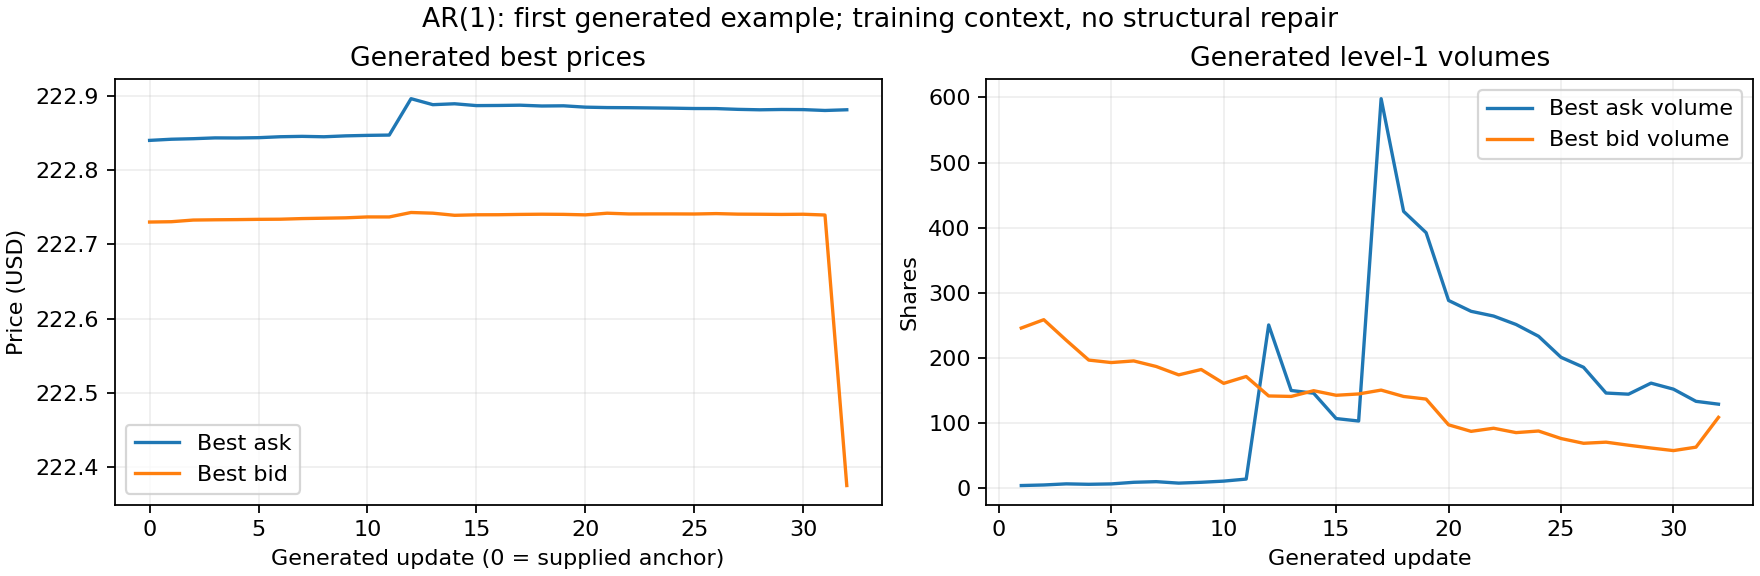

In [4]:
initial = report["initial_experiment"]
fit, generated = initial["fit"], initial["generation"]
facts = [("Training pairs", f"{fit['training_pairs']:,}"), ("Coefficients", fit["coefficient_count"]),
         ("Training one-step MSE (scaled)", f"{fit['training_one_step_mse_scaled']:.6f}"),
         ("Spectral radius", f"{fit['spectral_radius']:.6f}"), ("CPU fit only (s)", f"{fit['fit_seconds']:.4f}"),
         ("Generated shape", str(generated["generated_shape"])),
         ("Feature rollout only (s)", f"{generated['generation_seconds']:.6f}"),
         ("All decoded values finite", generated["all_decoded_values_finite"]),
         ("Invalid snapshots, all levels", f"{100 * initial['integrity']['invalid_rate']:.2f}%")]
display(pd.DataFrame(facts, columns=["Initial measurement", "Result"]).set_index("Initial measurement"))
figure("initial_preview")

The best-level lines can look plausible while deeper levels are unordered. A spectral radius below one describes stable linear mean
dynamics; it does not establish book validity. This historical run's invalid rate uses different contexts from the validation experiment.

## 4. Tuning grid

Nine fits: p = 1, 2, 4; ridge = 1e-6, 1e-4, 1e-2. Each uses seeds 42, 43, 44. Selection minimises mean invalid-book rate first,
then mean KL, then ACF error; p and ridge break any remaining ties. The selected configuration need not win on every measure.

,p,Ridge,Invalid (%),Spread KL,Return KL,ACF error
0,4,1e-06,91.38021,0.13229,0.59126,0.02597
1,2,1e-06,92.38426,0.14234,0.59486,0.02678
2,1,1e-06,92.64853,0.14092,0.60780,0.02447
3,1,1e-04,92.92438,0.15101,0.60581,0.01881
4,2,1e-04,93.00540,0.16376,0.60073,0.02101
5,2,1e-02,93.00637,0.16711,0.56514,0.02946
6,4,1e-04,93.06520,0.15660,0.59335,0.01932
7,1,1e-02,93.09992,0.14912,0.54058,0.02825
8,4,1e-02,93.10860,0.16582,0.59947,0.03000


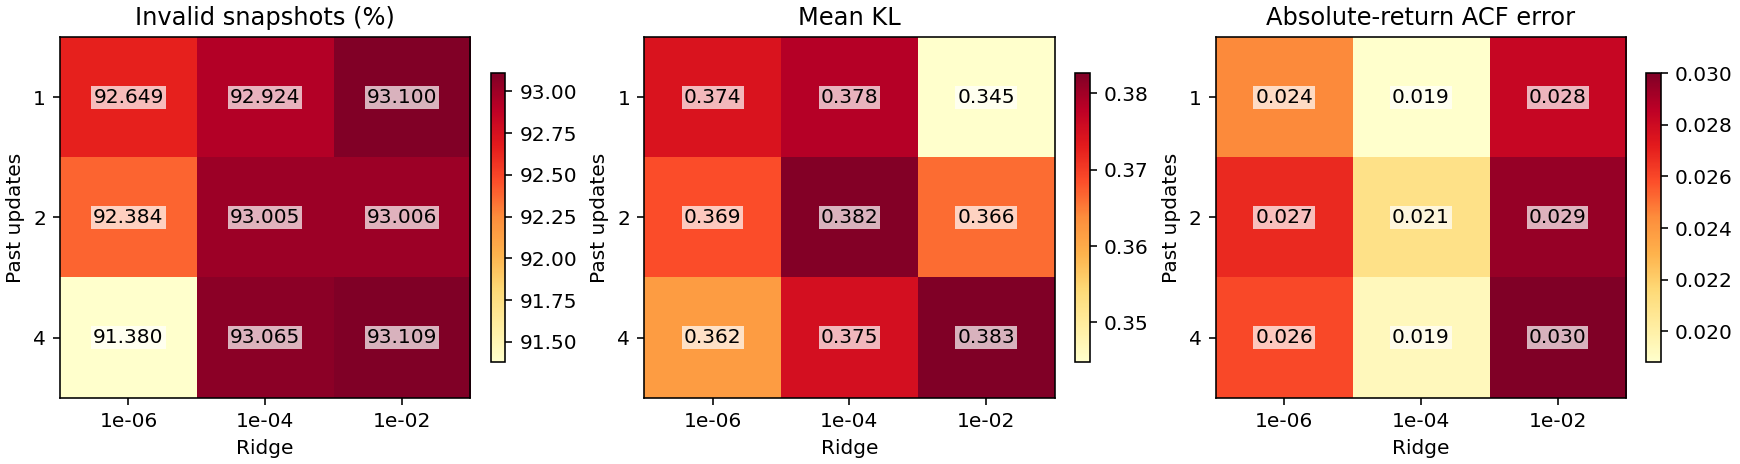

In [5]:
ranked = grid.sort_values(["invalid_rate_mean", "mean_kl_mean", "abs_return_acf_mae_mean"])
columns = {"lags": "p", "ridge": "Ridge", "invalid_rate_mean": "Invalid (%)", "kl_spread_mean": "Spread KL",
           "kl_mid_return_mean": "Return KL", "abs_return_acf_mae_mean": "ACF error"}
table = ranked[list(columns)].rename(columns=columns).copy()
table["Invalid (%)"] *= 100
display(table.reset_index(drop=True).style.format({"p": "{:.0f}", "Ridge": "{:.0e}", **{c: "{:.5f}" for c in list(columns.values())[2:]}}))
figure("grid")

## 5. Structural validity

A snapshot is invalid if any of its ten levels violates strict ask/bid ordering, positive prices, positive best spread, nonnegative
volume or finiteness. Categories overlap; do not add their percentages. Real validation snapshots pass all these checks.

In [6]:
checks = [("crossed_rate", "Nonpositive best spread"), ("ask_order_rate", "Unordered asks"),
          ("bid_order_rate", "Unordered bids"), ("negative_volume_rate", "Negative volume"),
          ("nonpositive_price_rate", "Nonpositive prices"), ("nonfinite_rate", "Non-finite values"),
          ("invalid_rate", "Any violation")]
rows = [[label, f"{100 * report['real_validity'][key]:.2f}", mean_sd(original, key, 100, 3), mean_sd(selected, key, 100, 3)]
        for key, label in checks]
display(pd.DataFrame(rows, columns=["Violation (%)", "Real", "Original", "Selected"]).set_index("Violation (%)"))

,Real,Original,Selected
Violation (%),,,
Nonpositive best spread,0.00,2.964 ± 0.449,2.037 ± 0.403
Unordered asks,0.00,82.823 ± 0.830,79.451 ± 0.140
Unordered bids,0.00,82.357 ± 0.284,78.734 ± 0.710
Negative volume,0.00,3.157 ± 0.211,2.646 ± 0.118
Nonpositive prices,0.00,0.000 ± 0.000,0.000 ± 0.000
Non-finite values,0.00,0.000 ± 0.000,0.000 ± 0.000
Any violation,0.00,92.924 ± 0.057,91.380 ± 0.163


## 6. Distributions and temporal behaviour

KL uses real || generated distributions, natural logs, 50 equally spaced training-range bins, two tail bins and 1e-8 probability
smoothing. All invalid finite books remain in the calculation. The plots show seed-mean histograms; reported KL is computed per seed first.

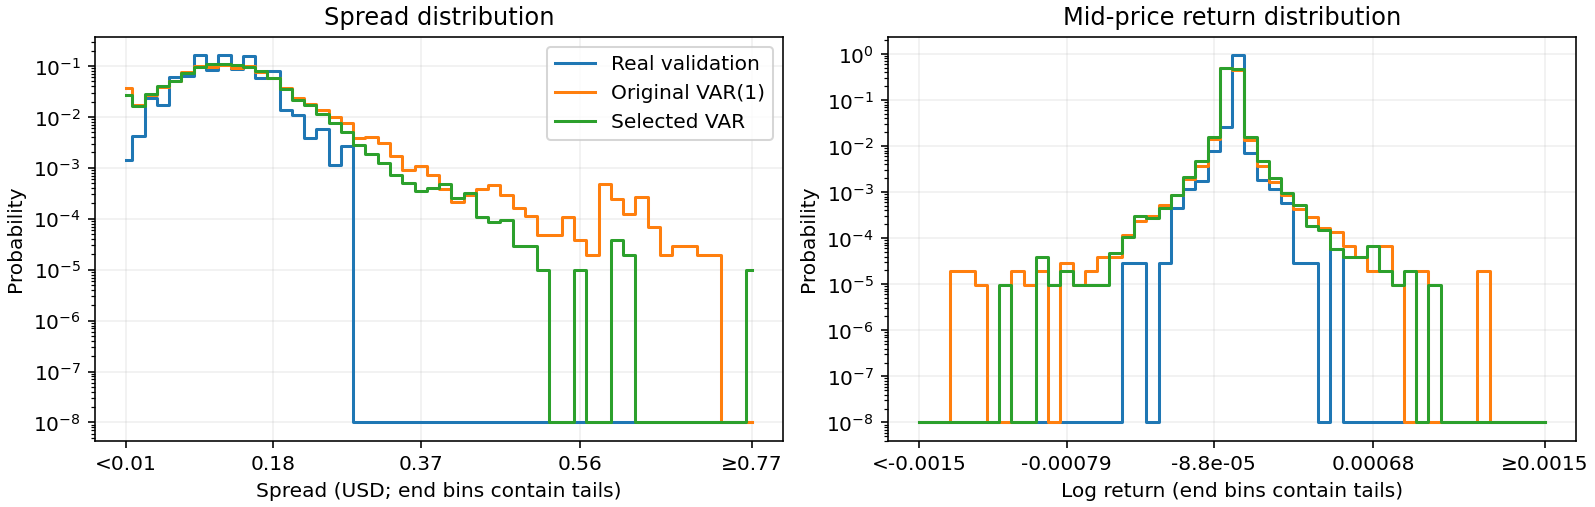

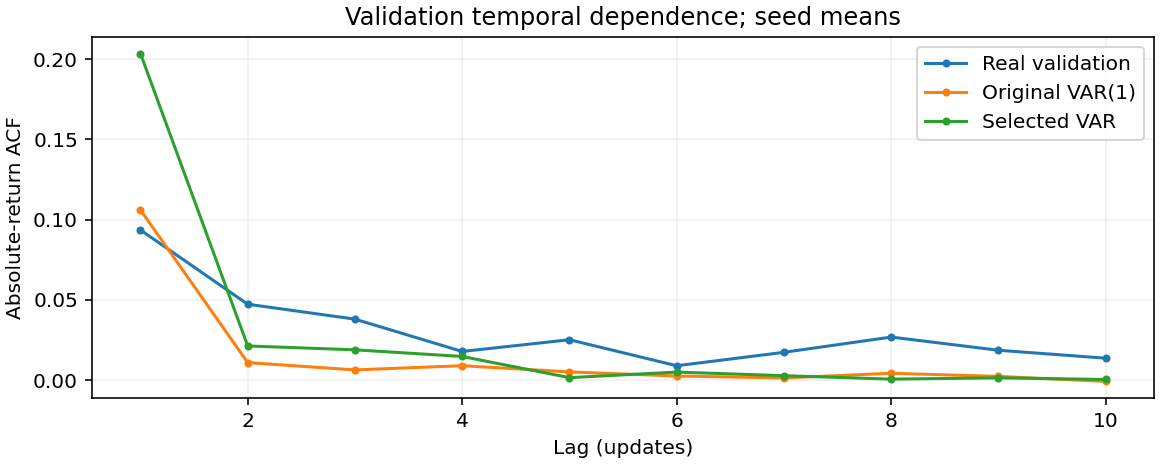

In [7]:
figure("distributions")
figure("acf", width=850)

The absolute-return ACF uses a global mean and the full squared-deviation sum as denominator, without pairs crossing window boundaries.
Error is mean absolute deviation from real ACF over lags 1–10. The tuned model overshoots the first lag; neither version captures the
later-lag dependence well. A 32-update analysis does not establish long-run volatility clustering or tail-risk fidelity.

## 7. Fixed example comparisons

First three eligible validation windows, first seed; selected before viewing results. Real and generated futures share an anchor,
but a sampled future is not expected to reproduce every realised jump. The line plots show the best level; the checks cover all ten.

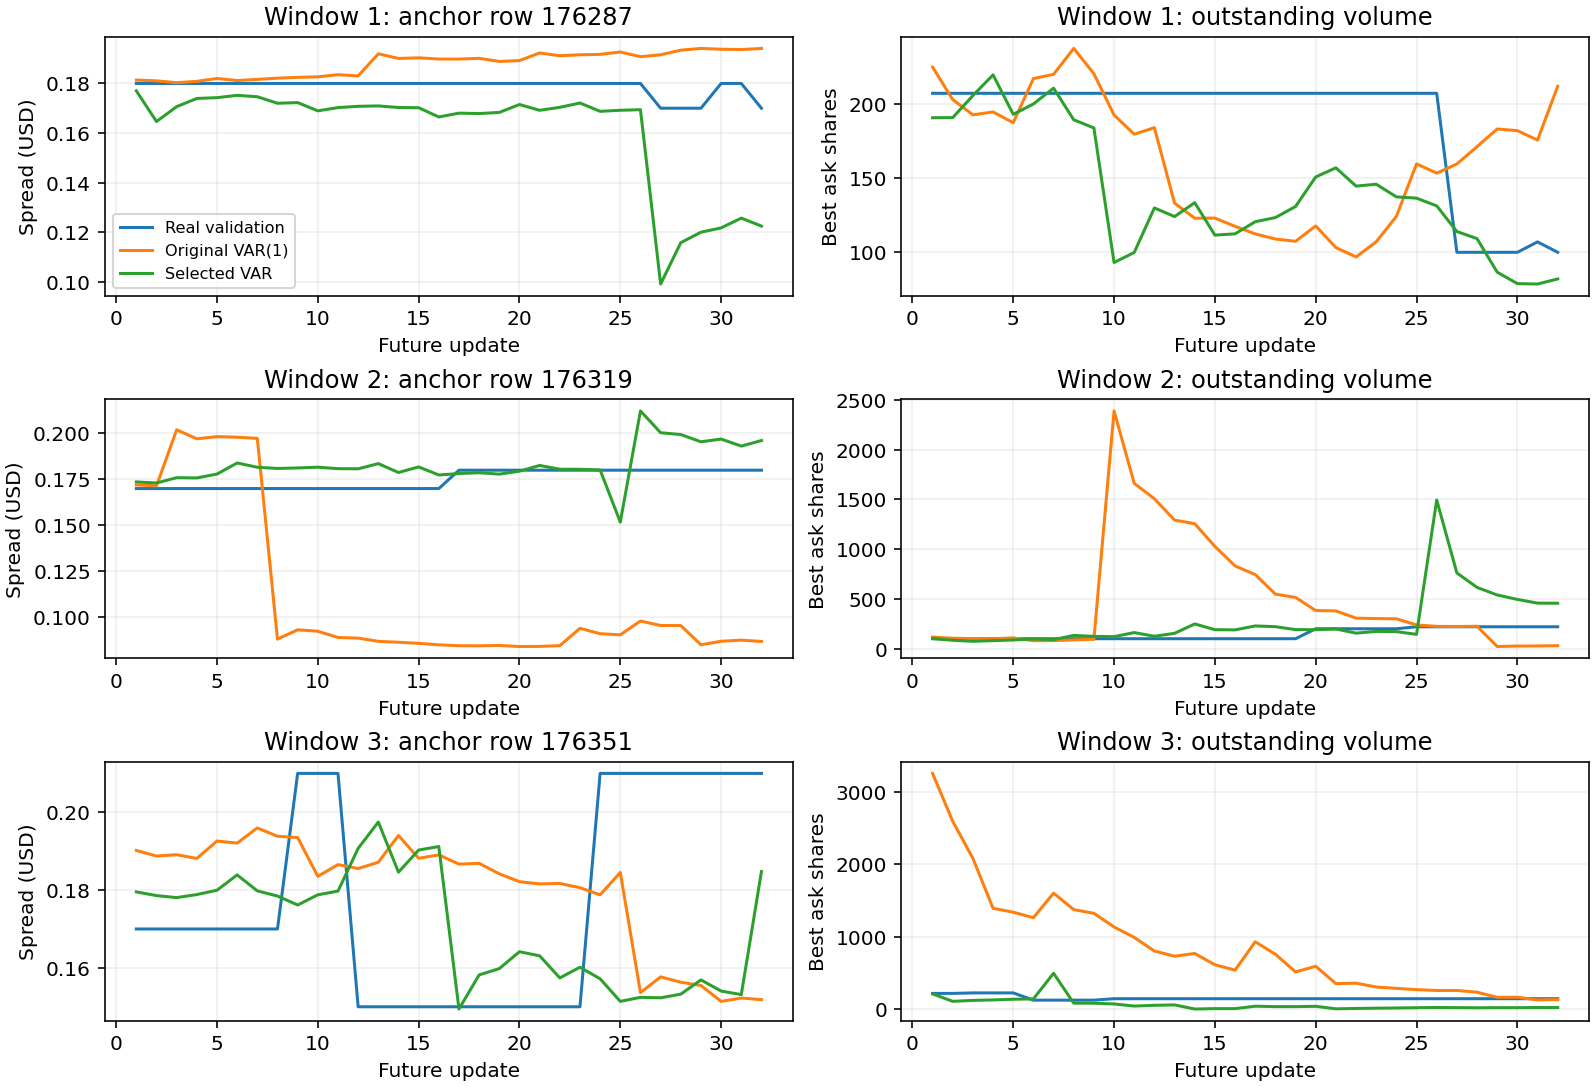

Window,Model,Invalid (%),Unordered asks (%),Unordered bids (%),Min spread ($)
1,Real,0.000,0.000,0.000,0.170
1,Original,90.625,84.375,90.625,0.180
1,Selected,100.000,100.000,93.750,0.099
2,Real,0.000,0.000,0.000,0.170
2,Original,87.500,12.500,87.500,0.084
2,Selected,100.000,93.750,93.750,0.152
3,Real,0.000,0.000,0.000,0.150
3,Original,100.000,100.000,71.875,0.151
3,Selected,78.125,62.500,78.125,0.149


In [8]:
figure("examples")
examples = pd.DataFrame(report["example_diagnostics"])
columns = ["window", "model", "invalid_rate", "ask_order_rate", "bid_order_rate", "minimum_spread_usd"]
table = examples[columns].copy()
table[["invalid_rate", "ask_order_rate", "bid_order_rate"]] *= 100
table.columns = ["Window", "Model", "Invalid (%)", "Unordered asks (%)", "Unordered bids (%)", "Min spread ($)"]
display(table.style.format({c: "{:.3f}" for c in table.columns[2:]}).hide(axis="index"))

Depth heatmaps use one colour scale for all panels. Rows are ask levels 10→1 then bid levels 1→10. Signed log volume preserves negative
values visibly. These plots describe volume structure; the table above diagnoses price-ladder failures that a volume image cannot show.
Depth SSIM has not yet been measured and is not inferred from visual similarity.

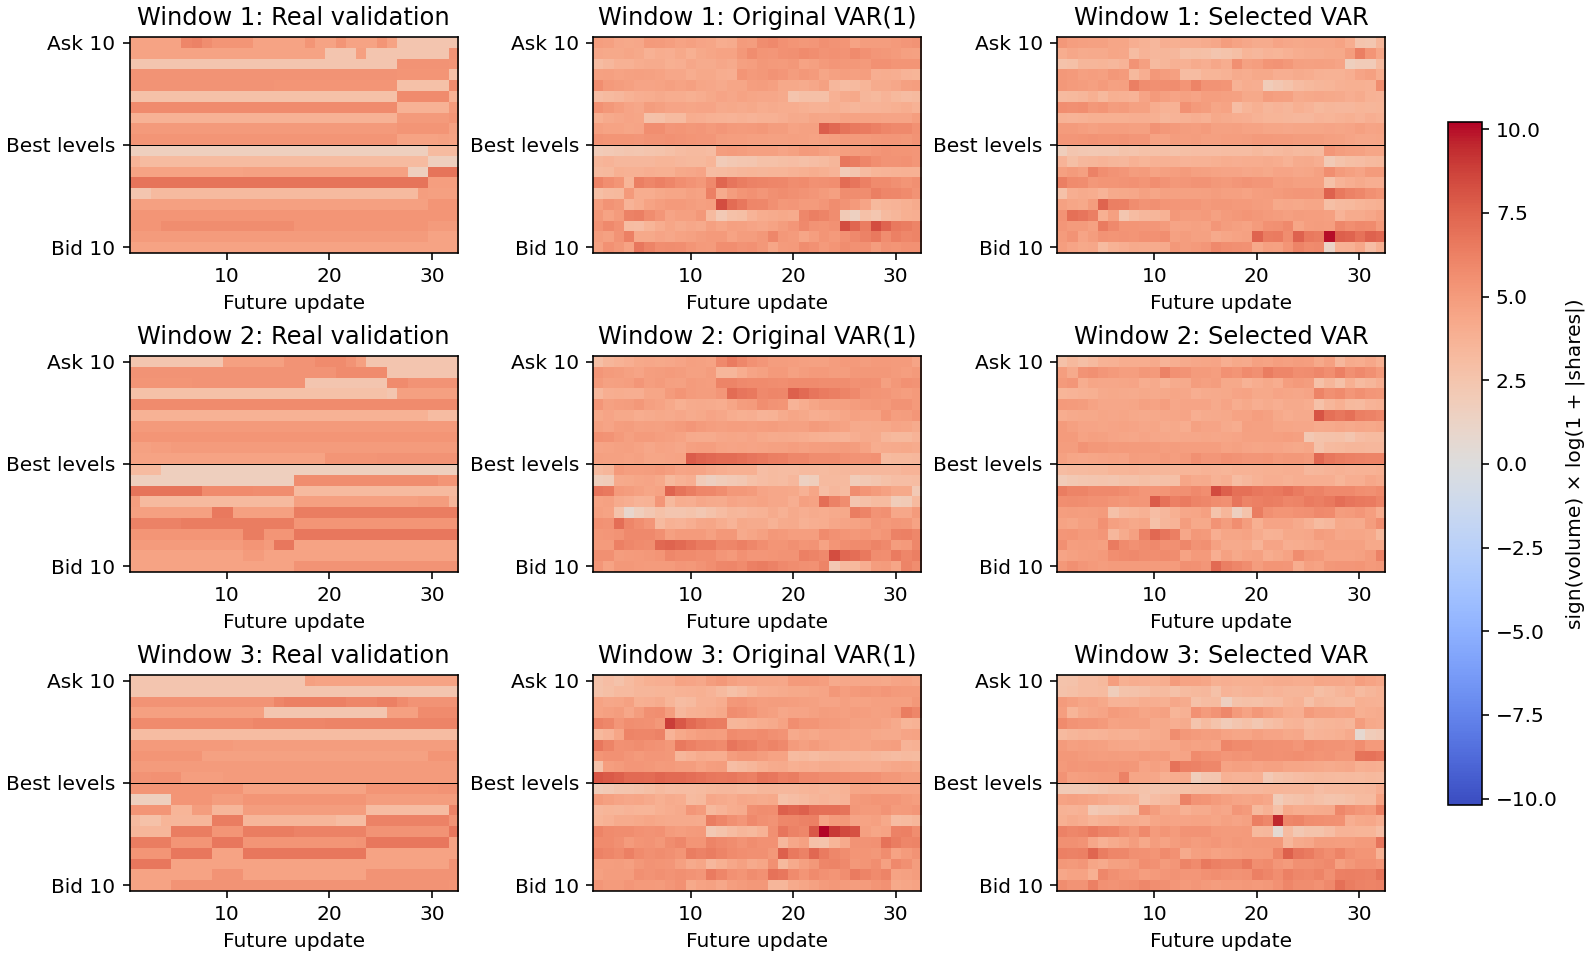

In [9]:
figure("depth")

## 8. Fit, runtime and verification

Current fits use CPU float64 and four threads. Candidate fit times allocate one-third of each lag order's shared SVD time, then add
its own ridge solve and residual calculation. Generation timing covers feature rollout only. GPU training memory was not measured.

In [10]:
resources = []
for label, row in [("Original", original), ("Selected", selected)]:
    resources.append([label, int(row.coefficient_count), row.training_one_step_mse, row.validation_one_step_mse,
                      row.spectral_radius, row.fit_seconds, row.generation_seconds_mean,
                      report["validation_windows"] / row.generation_seconds_mean])
display(pd.DataFrame(resources, columns=["Model", "Coefficients", "Train MSE", "Validation MSE", "Radius",
                                      "Fit share (s)", "Rollout (s)", "Sequences/s"]).set_index("Model").round(6))
verification = report["refactor_verification"]
benchmark = verification["benchmark"]
before, after = benchmark["before_median"], benchmark["after_median"]
display(pd.DataFrame([["Complete grid", before["wall_seconds"], after["wall_seconds"]],
                      ["Fitting work", before["fit_seconds"], after["fit_seconds"]]],
                     columns=["Median of 3 runs (s)", "Before refactor", "After refactor"]).set_index("Median of 3 runs (s)").round(3))
display(Markdown(f"The grid is {100 * (1 - after['wall_seconds'] / before['wall_seconds']):.1f}% faster in this comparison. "
                 "Both versions include data loading and saving but exclude interpreter startup and plotting. "
                 "The new implementation shares three SVDs instead of nine, decodes batches together and caches real validation statistics."))
print(f"Regression checks: {verification['tests_passed']} passed. Same selected candidate: {verification['same_selection']}.")
print(f"Largest measured metric change: {max(verification['maximum_metric_changes'].values()):.2e}.")

,Coefficients,Train MSE,Validation MSE,Radius,Fit share (s),Rollout (s),Sequences/s
Model,,,,,,,
Original,1640,0.002189,0.001712,0.976224,0.120681,0.027944,38648.357242
Selected,6440,0.002120,0.001689,0.984912,0.457425,0.042673,25308.624582


,Before refactor,After refactor
Median of 3 runs (s),,
Complete grid,11.563,7.794
Fitting work,5.077,2.435


The grid is 32.6% faster in this comparison. Both versions include data loading and saving but exclude interpreter startup and plotting. The new implementation shares three SVDs instead of nine, decodes batches together and caches real validation statistics.

Regression checks: 20 passed. Same selected candidate: True.
Largest measured metric change: 1.32e-14.


## 9. Conclusion and remaining comparison work

Retain the original and tuned AR models as benchmarks. Tuning provides a small distributional improvement but does not solve the
structural failures, and worsens this temporal measure. The unrestricted feature representation permits invalid ladders and volumes;
increasing lag order alone does not enforce market constraints.

In [11]:
status = [("Zero invalid snapshots", "Not met" if selected.invalid_rate_mean > 0 else "Met"),
          ("Spread KL ≤ 0.1", "Not met" if selected.kl_spread_mean > 0.1 else "Met"),
          ("Mid-return KL ≤ 0.1", "Not met" if selected.kl_mid_return_mean > 0.1 else "Met"),
          ("Depth SSIM > 0.6", "Not measured"), ("TimeGAN comparison", "Pending"), ("Final test evaluation", "Pending")]
display(pd.DataFrame(status, columns=["Criterion", "Selected baseline"]).set_index("Criterion"))

,Selected baseline
Criterion,
Zero invalid snapshots,Not met
Spread KL ≤ 0.1,Not met
Mid-return KL ≤ 0.1,Not met
Depth SSIM > 0.6,Not measured
TimeGAN comparison,Pending
Final test evaluation,Pending


This is one stock on one trading day, with observed anchors and event-time sequences. It does not test cross-day generalisation,
event-arrival times or an unconditional market simulator. Freeze metric definitions and document comparable conditioning when adding
TimeGAN; use test data only after model choices are fixed.

## Appendix: complete seed results and reproducibility

All historical and current numeric results are in `reports/ar/results.json`; figures sit alongside it. The notebook embeds displayed
outputs and can rerun from that bundle without raw data, weights or ignored preview arrays. Recomputing requires the external dataset.
Model weights and larger generated arrays remain under ignored `outputs/`. The report checks source and figure hashes on load.

In [12]:
runs = pd.DataFrame(report["runs"])
fields = ["candidate", "seed", "status", "invalid_rate", "kl_spread", "kl_mid_return", "abs_return_acf_mae"]
display(HTML("<details><summary>All 27 validation evaluations</summary>" + runs[fields].to_html(index=False, float_format=lambda x: f"{x:.6f}") + "</details>"))
files = pd.DataFrame(report["input_files"])[["name", "bytes", "sha256"]]
display(HTML("<details><summary>Input provenance and environment</summary>" + files.to_html(index=False) + "</details>"))
print(f"PyTorch {report['torch_version']}; NumPy {report['numpy_version']}; seeds {SEEDS}; test evaluated: {report['test_evaluated']}.")

candidate,seed,status,invalid_rate,kl_spread,kl_mid_return,abs_return_acf_mae
p1_ridge1e-06,42,ok,0.926881,0.137223,0.622631,0.023852
p1_ridge1e-06,43,ok,0.924740,0.145246,0.596139,0.027189
p1_ridge1e-06,44,ok,0.927836,0.140287,0.604617,0.022362
p1_ridge0.0001,42,ok,0.929572,0.149591,0.622570,0.018257
p1_ridge0.0001,43,ok,0.928588,0.155228,0.595055,0.020734
p1_ridge0.0001,44,ok,0.929572,0.148214,0.599805,0.017453
p1_ridge0.01,42,ok,0.931655,0.142348,0.544869,0.028176
p1_ridge0.01,43,ok,0.929745,0.154127,0.538894,0.029121
p1_ridge0.01,44,ok,0.931597,0.150873,0.537980,0.027443
p2_ridge1e-06,42,ok,0.923987,0.156452,0.598714,0.024305


name,bytes,sha256
AMZN_2012-06-21_34200000_57600000_message_10.csv,11248750,c85a75b51f3616a683f825c2e03f984535e9329a8be5ab12325130d32223a2c5
AMZN_2012-06-21_34200000_57600000_orderbook_10.csv,63216242,decfe952b3fa06c9922dc8fba763a37a0fb032d4231767997e4abf2aa0d29b50


PyTorch 2.8.0+cu128; NumPy 2.2.6; seeds [42, 43, 44]; test evaluated: False.
